In [9]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
#matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import importlib
import lattice
import kmc
import loading as ld
import pickle
importlib.reload(lattice)
importlib.reload(kmc)
importlib.reload(ld)
#########################################
# Testing analytic LD in regular lattices
# - random fixed dipoles
# - should return effective kappa of 0.476
##########################################

rf= 26.5/(0.476)**(1/3)
tau = 351
r0= 20
n=10**3

LOAD_FIXED_KAPPA=False
FIXED_KAPPA = 0.476 #2/3
save = False
krot_dip = 0
PBC = [0,1]

nrounds = 10000#00

latt = np.loadtxt("lattice.txt")
X,Y,Z = latt[:,0],latt[:,1],latt[:,2]

dist_X = np.mean(X)
dist_Y = np.mean(Y)
dist_Z = np.mean(Z)

dX = X.max()-X.min() #+ dist_X
dY = Y.max()-Y.min()# + dist_Y
dZ = Z.max()-Z.min() #+ dist_Z
cutoff= 1000
L = np.array([dX,dY,dZ])

dim = len(L)

syst = ld.System(save=save,RF=rf,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
syst.make_lattice(loadcoord=True,loaddip=True)
results = Parallel(n_jobs=10,verbose=0)(delayed(kmc.kmc_run_fluor)(syst) for _ in range(nrounds))
out_dict = kmc.process_results(results,dim=len(L),RF=rf,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

kappa2 = out_dict['kappa2_list_MSD']
LD_calc = out_dict['LD_calc']
kappa2_mean = np.mean(kappa2)
print('kappa2 médio:',kappa2_mean)
print('LD calculado pelo MSD:', LD_calc)


this program run with <Kappa^2> = 1.33314
DONE LOADING LATTICE
Dana = 12.96 Dlasttime = 102.24 Dmean = 101.65
LDana =67.43 LDcalc=190.30 LD_d=188.89
kappa2 médio: 3.7906500413382904
LD calculado pelo MSD: 190.29506405182926


In [10]:
# fixo 2/3

rf= 26.5/(0.476)**(1/3)
tau = 351
r0= 20
n=10**3

LOAD_FIXED_KAPPA=  True
FIXED_KAPPA = 2/3
save = False
krot_dip = 0
PBC = [0,1]

nrounds = 10000#00

latt = np.loadtxt("lattice.txt")
X,Y,Z = latt[:,0],latt[:,1],latt[:,2]

dist_X = np.mean(X)
dist_Y = np.mean(Y)
dist_Z = np.mean(Z)

dX = X.max()-X.min() #+ dist_X
dY = Y.max()-Y.min()# + dist_Y
dZ = Z.max()-Z.min() #+ dist_Z
cutoff= 1000
L = np.array([dX,dY,dZ])

dim = len(L)

syst = ld.System(save=save,RF=rf,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
syst.make_lattice(loadcoord=True,loaddip=True)
results = Parallel(n_jobs=10,verbose=0)(delayed(kmc.kmc_run_fluor)(syst) for _ in range(nrounds))
out_dict = kmc.process_results(results,dim=len(L),RF=rf,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

kappa2 = out_dict['kappa2_list_MSD']
LD_calc = out_dict['LD_calc']
kappa2_mean = np.mean(kappa2)
print('kappa2 médio:',kappa2_mean)
print('LD calculado pelo MSD:', LD_calc)



this program run with <Kappa^2> = 0.66667
DONE LOADING LATTICE
Dana = 18.14 Dlasttime = 73.39 Dmean = 72.98
LDana =79.80 LDcalc=160.12 LD_d=160.05
kappa2 médio: 2.6836541538371645
LD calculado pelo MSD: 160.1157121272024


In [11]:
# fixo 0.476

rf= 26.5/(0.476)**(1/3)
tau = 351
r0= 20
n=10**3

LOAD_FIXED_KAPPA= True
FIXED_KAPPA = 0.476 #2/3
save = False
krot_dip = 0
PBC = [0,1]

nrounds = 10000#00

latt = np.loadtxt("lattice.txt")
X,Y,Z = latt[:,0],latt[:,1],latt[:,2]

dist_X = np.mean(X)
dist_Y = np.mean(Y)
dist_Z = np.mean(Z)

dX = X.max()-X.min() #+ dist_X
dY = Y.max()-Y.min()# + dist_Y
dZ = Z.max()-Z.min() #+ dist_Z
cutoff= 1000
L = np.array([dX,dY,dZ])

dim = len(L)

syst = ld.System(save=save,RF=rf,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
syst.make_lattice(loadcoord=True,loaddip=True)
results = Parallel(n_jobs=10,verbose=0)(delayed(kmc.kmc_run_fluor)(syst) for _ in range(nrounds))
out_dict = kmc.process_results(results,dim=len(L),RF=rf,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

kappa2 = out_dict['kappa2_list_MSD']
LD_calc = out_dict['LD_calc']
kappa2_mean = np.mean(kappa2)
print('kappa2 médio:',kappa2_mean)
print('LD calculado pelo MSD:', LD_calc)


this program run with <Kappa^2> = 0.47600
DONE LOADING LATTICE
Dana = 12.96 Dlasttime = 51.74 Dmean = 52.71
LDana =67.43 LDcalc=134.47 LD_d=136.02
kappa2 médio: 1.8929612687825026
LD calculado pelo MSD: 134.47499655116513


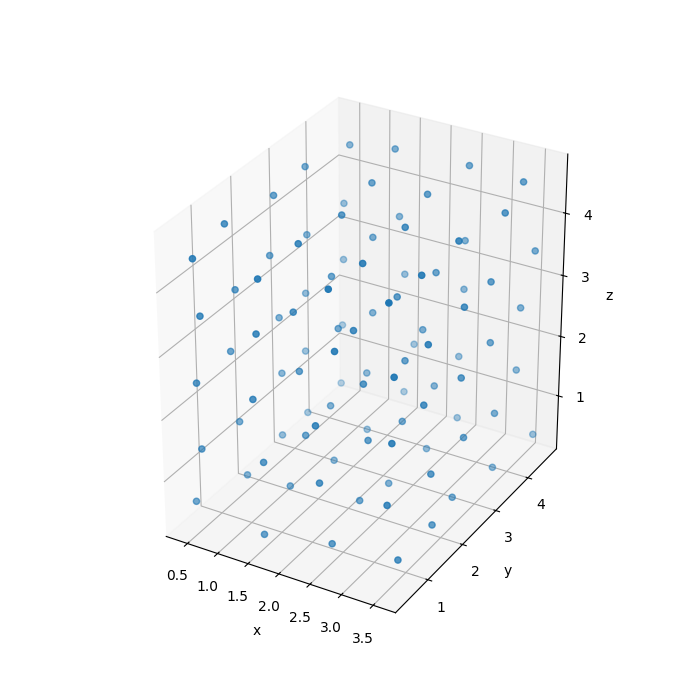

In [29]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt

R = np.loadtxt("lattice.txt")

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(R[:,0], R[:,1], R[:,2], s=20)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect(np.ptp(R, axis=0))

plt.show()

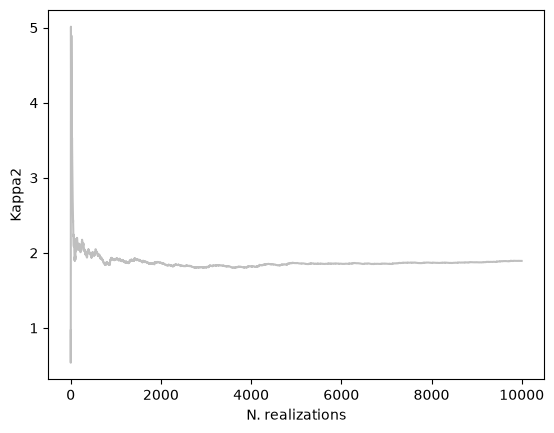

In [12]:
#ploting kappa with the images
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import importlib
import pickle
plt.clf()
plt.close()

D_nokappa=(1/tau)*(((rf)**6)/(r0**4))
cums = np.zeros(nrounds)
Ld_ana_wihtoutkappa = (rf**3)/(r0**2)


Ds = np.array([x for x in out_dict['D']])
Dlist = np.array([x[0] for x in out_dict['Dlist']])
kappa2_from_out = np.array([x for x in out_dict['kappa2_list_MSD']])
mean_from_image = np.array([ np.mean(kappa2_from_out[:n]) for n in range(1,len(kappa2_from_out)) ])
plt.plot(np.arange(len(mean_from_image)),mean_from_image,c='grey',alpha=0.5)

plt.xlabel('N. realizations')
plt.ylabel('Kappa2')
plt.show()


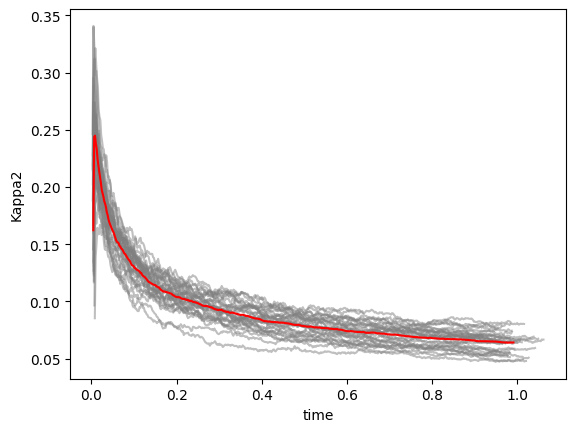

0.0640676650065506


In [8]:
#plotting kappa but during time


with open(f"out_kmc1D_{rf}_{tau}.pkl", "rb") as f:
    outs=pickle.load(f)

nmeas = 500
Ttot = np.zeros(nmeas)
kappas=np.zeros(nmeas)

for i in range(images):
    out_dict = outs[i]
    t,k =  out_dict['Dtime']
    plt.plot(t,k,c='gray',alpha=0.5)
    Ttot +=t
    kappas+= k
    
Ttot   = Ttot/images
kappas = kappas/images
#means = np.array([ np.mean(cums[:n]) for n in range(1,len(cums)) ])
#kappa2=(means/Ld_ana_wihtoutkappa)**2

#kappa2=(means/D_nokappa)
plt.xlabel('time')
plt.ylabel('Kappa2')
plt.plot(Ttot,kappas,c='r')
plt.show()
print(kappas[-1])

In [15]:
#multipe executions
import numpy as np
import scipy
import pandas as pd
import matplotlib
#matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import importlib
import lattice
import kmc
import loading as ld
import pickle
importlib.reload(lattice)
importlib.reload(kmc)

#########################################
# Testing analytic LD in regular lattices
# - random fixed dipoles
# - should return effective kappa of 0.476
##########################################
tau = 1
rf = 1
r0=1
n=1000

LOAD_FIXED_KAPPA=False
FIXED_KAPPA = 0.476 #2/3
save = False
cutoff = r0
krot_dip = 0
PBC = [0]
L = r0*np.array([n])
nrounds = 1000#00
dim = len(L)

Ds,Lds = [],[]

images = 50
outs = []
for i in range(images):
    syst = ld.System(save=save,RF=rf,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
    syst.make_lattice()
    results = Parallel(n_jobs=15,verbose=0)(delayed(kmc.kmc_run_fluor)(syst) for _ in range(nrounds))
    out_dict = kmc.process_results(results,dim=len(L),RF=rf,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)
    outs.append(out_dict)
with open("out_kmc1D.pkl", "wb") as f:
    pickle.dump(outs, f)

this program run with <Kappa^2> = 0.68216
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.45 Dmean = 0.50
LDana =0.69 LDcalc=0.66 LD_d=0.71
this program run with <Kappa^2> = 0.66082
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.49 Dmean = 0.51
LDana =0.69 LDcalc=0.71 LD_d=0.72
this program run with <Kappa^2> = 0.68186
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.48 Dmean = 0.51
LDana =0.69 LDcalc=0.69 LD_d=0.71
this program run with <Kappa^2> = 0.65978
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.41 Dmean = 0.53
LDana =0.69 LDcalc=0.64 LD_d=0.73
this program run with <Kappa^2> = 0.68726
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.39 Dmean = 0.45
LDana =0.69 LDcalc=0.63 LD_d=0.67
this program run with <Kappa^2> = 0.69812
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.43 Dmean = 0.49
LDana =0.69 LDcalc=0.65 LD_d=0.70
this program run with <Kappa^2> = 0.67773
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.49 Dmean = 0.63
LDana =0.69 LDcalc=0.71 LD_d=0.79
this program run with <Kapp

ValueError: operands could not be broadcast together with shapes (600,) (1000,) (600,) 

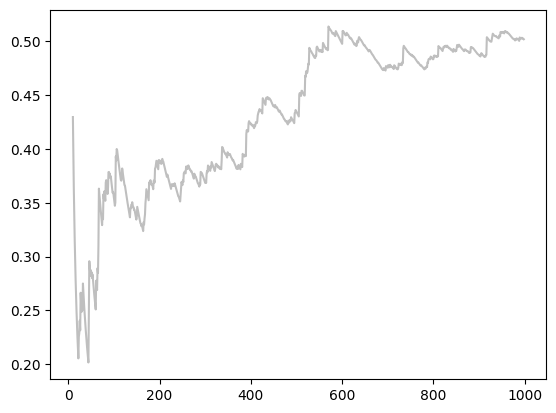

In [18]:
with open("out_kmc1D.pkl", "rb") as f:
    outs=pickle.load(f)

D_nokappa=(1/tau)*(((rf)**6)/(r0**4))
cums = np.zeros(nrounds)
slice_vec=10
Ld_ana_wihtoutkappa = (rf**3)/(r0**2)
for i in range(images):
    out_dict = outs[i]
    Ds = np.array([x for x in out_dict['D']])
    Dlist = np.array([x[0] for x in out_dict['Dlist']])
    means = np.array([ np.mean(Dlist[:n]) for n in range(1,len(Dlist)) ])
    kappa2=means/D_nokappa

    plt.plot(np.arange(len(kappa2))[slice_vec:],kappa2[slice_vec:],c='grey',alpha=0.5)

    #MSDs_f = np.array([x for x in out_dict['MSDs_f']])
    
    #Lds    = (1/np.sqrt(2*dim))*np.sqrt(MSDs_f)
    
    cums+=Dlist#Lds
cums  = cums/images
means = np.array([ np.mean(cums[:n]) for n in range(1,len(cums)) ])
#kappa2=(means/Ld_ana_wihtoutkappa)**2

kappa2=(means/D_nokappa)
plt.plot(np.arange(len(means))[slice_vec:],kappa2[slice_vec:],c='r')
plt.show()